# <span style="color: #a855f7">Tree-based models</span>

<span style="color: #a855f7">Decision Tree, Random Forest і XGBoost для прогнозу ціни житла, LogisticRegression для класифікації відносно медіани, однакові ознаки, відтворювані split</span>

In [1]:
from html import escape

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    r2_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.utils import Bunch
from xgboost import XGBRegressor

TEST_SIZE = 0.2
RANDOM_STATE = 42
COLORS = ["#a855f7", "#f472b6", "#60a5fa"]


def colorize(value, *, index=True):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        table = value.to_frame() if isinstance(value, pd.Series) else value
        html = table.to_html(border=0, index=index).replace(
            '<table ', '<table style="color: #a855f7; margin-left: 0; margin-right: auto; border-collapse: collapse" '
        )
        for tag in ("th", "td"):
            html = html.replace(
                f"<{tag}>",
                f'<{tag} style="padding: 6px 12px; border-bottom: 1px solid #746a80">',
            )
        display(HTML(html))
    else:
        display(HTML(f'<pre style="color: #a855f7; background: transparent">{escape(str(value))}</pre>'))


plt.style.use("dark_background")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "figure.facecolor": "#111116",
    "axes.facecolor": "#111116",
    "axes.edgecolor": "#746a80",
    "axes.labelcolor": "#e9d5ff",
    "axes.titlecolor": "#e9d5ff",
    "axes.titlesize": 13,
    "text.color": "#e9d5ff",
    "xtick.color": "#d8c8ed",
    "ytick.color": "#d8c8ed",
    "grid.color": "#746a80",
    "grid.alpha": 0.25,
    "font.size": 10,
})

## <span style="color: #a855f7">California Housing and regression split</span>

<span style="color: #a855f7">20640 спостережень, 4 ознаки: MedInc, HouseAge, AveRooms, AveBedrms, ціль MedHouseVal у одиницях 100000 USD, дані історичні, перший fetch потребує інтернету за відсутності кешу, split 80/20 з random_state = 42</span>

In [2]:
data = fetch_california_housing(as_frame=True, return_X_y=False)
if not isinstance(data, Bunch) or not isinstance(data.frame, pd.DataFrame):
    raise TypeError("Expected a California Housing dataset with a pandas DataFrame")
features = ["MedInc", "HouseAge", "AveRooms", "AveBedrms"]
required_columns = features + ["MedHouseVal"]
if not set(required_columns).issubset(data.frame.columns):
    raise ValueError("California Housing is missing required columns")
selected_data = data.frame[required_columns].copy()
if not np.isfinite(selected_data.to_numpy(dtype=float)).all():
    raise ValueError("Selected features and target must contain only finite numeric values")
X = selected_data[features].copy()
y = selected_data["MedHouseVal"].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE,
)
if not X_train.index.intersection(X_test.index).empty:
    raise ValueError("Regression train and test must not overlap")
colorize(f"Dataset rows: {len(X)} | selected features: {X.shape[1]}")
colorize("Selected features and target: first 5 rows")
colorize(selected_data.head())
colorize(pd.DataFrame({
    "split": ["train", "test"],
    "rows": [len(X_train), len(X_test)],
    "features": [X_train.shape[1], X_test.shape[1]],
}), index=False)

,MedInc,HouseAge,AveRooms,AveBedrms,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,4.526
1,8.3014,21.0,6.238137,0.971880,3.585
2,7.2574,52.0,8.288136,1.073446,3.521
3,5.6431,52.0,5.817352,1.073059,3.413
4,3.8462,52.0,6.281853,1.081081,3.422


split,rows,features
train,16512,4
test,4128,4


## <span style="color: #a855f7">Decision tree regression</span>

<span style="color: #a855f7">DecisionTreeRegressor з max_depth=4 і random_state=42, модель навчається лише на train, R² обчислюється на test, масштабування для розбиттів дерева не потрібне</span>

In [3]:
tree_model = DecisionTreeRegressor(max_depth=4, random_state=RANDOM_STATE)
tree_model.fit(X_train, y_train)
tree_predictions = np.asarray(tree_model.predict(X_test), dtype=float)
tree_r2 = r2_score(y_test, tree_predictions)
colorize(pd.DataFrame({
    "model": ["Decision Tree"],
    "max_depth": [tree_model.get_depth()],
    "leaves": [tree_model.get_n_leaves()],
    "test R²": [tree_r2],
}).round(4), index=False)

model,max_depth,leaves,test R²
Decision Tree,4,16,0.5075


## <span style="color: #a855f7">Decision tree vs random forest</span>

<span style="color: #a855f7">ті самі ознаки і той самий split, RandomForestRegressor має n_estimators=100 і random_state=42, дерево з попереднього розділу використовується повторно без зайвого навчання, n_jobs=-1 дозволяє паралельну роботу CPU</span>

In [4]:
forest_model = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
forest_model.fit(X_train, y_train)
forest_predictions = np.asarray(forest_model.predict(X_test), dtype=float)
forest_r2 = r2_score(y_test, forest_predictions)
tree_forest_comparison = pd.DataFrame({
    "model": ["Decision Tree", "Random Forest"],
    "test R²": [tree_r2, forest_r2],
})
colorize(tree_forest_comparison.round(4), index=False)
colorize(f"Random Forest minus Decision Tree test R²: {forest_r2 - tree_r2:+.4f}")

model,test R²
Decision Tree,0.5075
Random Forest,0.5879


## <span style="color: #a855f7">XGBoost comparison</span>

<span style="color: #a855f7">XGBRegressor з n_estimators=200, learning_rate=0.1, max_depth=5 і random_state=42, train і test залишаються тими самими, test не використовується для ранньої зупинки чи підбору параметрів</span>

model,test R²
Decision Tree,0.5075
Random Forest,0.5879
XGBoost,0.5993


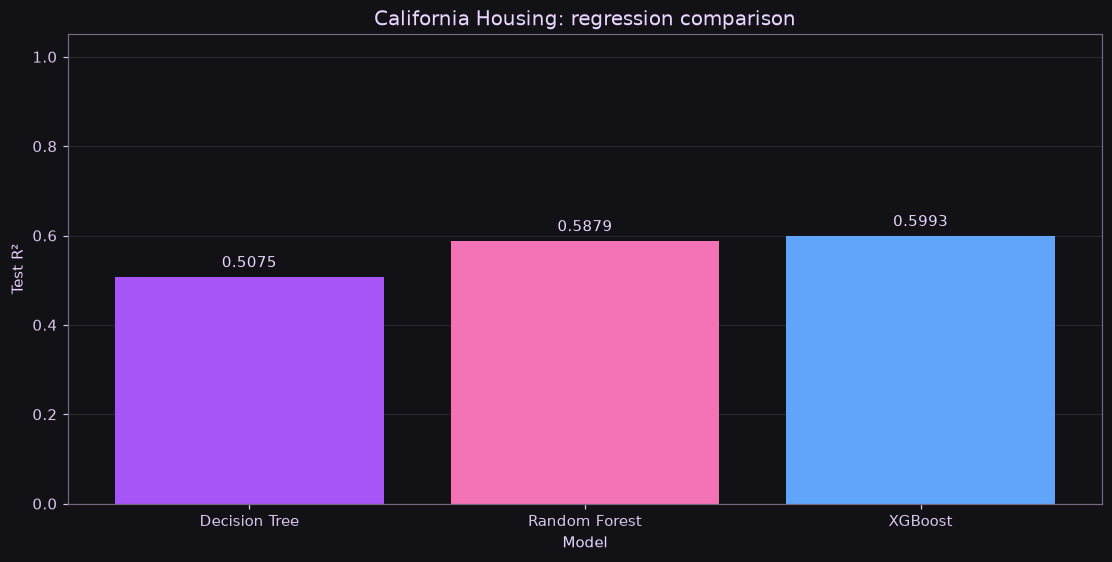

In [5]:
xgb_model = XGBRegressor(
    n_estimators=200, learning_rate=0.1, max_depth=5, random_state=RANDOM_STATE,
    n_jobs=4,
)
xgb_model.fit(X_train, y_train)
xgb_predictions = np.asarray(xgb_model.predict(X_test), dtype=float)
xgb_r2 = r2_score(y_test, xgb_predictions)
regression_comparison = pd.DataFrame({
    "model": ["Decision Tree", "Random Forest", "XGBoost"],
    "test R²": [tree_r2, forest_r2, xgb_r2],
})
colorize(regression_comparison.round(4), index=False)
colorize(f"XGBoost minus Random Forest test R²: {xgb_r2 - forest_r2:+.4f}")
best_regressor = regression_comparison.loc[regression_comparison["test R²"].idxmax(), "model"]
colorize(f"Highest R² on this test split: {best_regressor}")
fig, ax = plt.subplots(layout="constrained")
bars = ax.bar(regression_comparison["model"].tolist(), regression_comparison["test R²"].to_numpy(), color=COLORS)
ax.bar_label(bars, fmt="%.4f", padding=4)
ax.set(title="California Housing: regression comparison", xlabel="Model", ylabel="Test R²", ylim=(min(0, regression_comparison["test R²"].min() - 0.05), 1.05))
ax.grid(axis="y")
ax.set_axisbelow(True)
plt.show()

<span style="color: #a855f7">R² означає меншу суму квадратів помилок на цій test-вибірці, результати стосуються заданих 4 ознак і параметрів, один split не доводить універсальну перевагу алгоритму, R² безрозмірний і не є часткою точно вгаданих цін</span>

## <span style="color: #a855f7">Binary target and classification split</span>

<span style="color: #a855f7">за ТЗ поріг дорівнює np.median(y) для повної цілі, клас 1 - строго вище медіани, клас 0 - нижче або дорівнює, це окрема задача класифікації на тих самих 4 ознаках, split 80/20 з random_state = 42</span>

In [6]:
median_price = float(np.median(y))
y_class = (y > median_price).astype(int)
if set(y_class.unique()) != {0, 1}:
    raise ValueError("Classification requires both binary classes")
X_class_train, X_class_test, y_class_train, y_class_test = train_test_split(
    X, y_class, test_size=TEST_SIZE, random_state=RANDOM_STATE,
)
if not X_class_train.index.intersection(X_class_test.index).empty:
    raise ValueError("Classification train and test must not overlap")
class_counts = y_class.value_counts().sort_index()
class_distribution = pd.DataFrame({
    "class": [0, 1],
    "definition": ["Price at or below median", "Price above median"],
    "all rows": class_counts.to_numpy(),
    "train rows": y_class_train.value_counts().reindex([0, 1], fill_value=0).to_numpy(),
    "test rows": y_class_test.value_counts().reindex([0, 1], fill_value=0).to_numpy(),
})
colorize(f"Median target: {median_price:.5f} x 100000 USD = {median_price * 100000:.2f} USD")
colorize(class_distribution, index=False)

class,definition,all rows,train rows,test rows
0,Price at or below median,10323,8246,2077
1,Price above median,10317,8266,2051


## <span style="color: #a855f7">Logistic regression</span>

<span style="color: #a855f7">Pipeline зі StandardScaler і LogisticRegression(max_iter=1000), scaler навчається лише на classification train, позитивний клас - 1, Accuracy оцінює всі прогнози, Precision - правильність прогнозів класу 1, Recall - повноту виявлення класу 1, F1 - їхнє гармонійне середнє</span>

In [7]:
classifier = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000)),
])
classifier.fit(X_class_train, y_class_train)
class_predictions = np.asarray(classifier.predict(X_class_test), dtype=int)
classification_metrics = pd.DataFrame({
    "metric": ["Accuracy", "Precision", "Recall", "F1"],
    "value": [
        accuracy_score(y_class_test, class_predictions),
        precision_score(y_class_test, class_predictions, pos_label=1, zero_division=0),
        recall_score(y_class_test, class_predictions, pos_label=1, zero_division=0),
        f1_score(y_class_test, class_predictions, pos_label=1, zero_division=0),
    ],
})
colorize(classification_metrics.round(4), index=False)
np.testing.assert_allclose(classifier.named_steps["scaler"].mean_, X_class_train.mean().to_numpy())
colorize(f"Logistic regression iterations: {int(classifier.named_steps['model'].n_iter_[0])} / 1000")

metric,value
Accuracy,0.7875
Precision,0.7968
Recall,0.7684
F1,0.7823


## <span style="color: #a855f7">Confusion matrix</span>

<span style="color: #a855f7">рядки - реальні класи, стовпці - передбачені, TN: правильно визначено клас 0, TP: правильно визначено клас 1, FP: ціна помилково віднесена вище медіани, FN: житло вище медіани помилково віднесене до класу 0</span>

,Predicted class 0,Predicted class 1
Actual class 0,1675,402
Actual class 1,475,1576


outcome,count
TN,1675
FP,402
FN,475
TP,1576


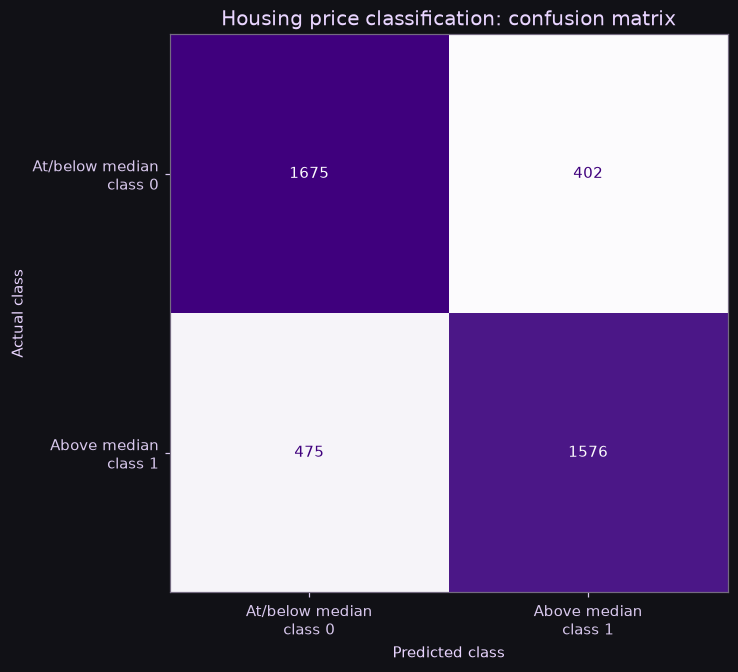

In [8]:
cm = confusion_matrix(y_class_test, class_predictions, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
colorize(pd.DataFrame(cm, index=["Actual class 0", "Actual class 1"], columns=["Predicted class 0", "Predicted class 1"]))
colorize(pd.DataFrame({
    "outcome": ["TN", "FP", "FN", "TP"],
    "count": [tn, fp, fn, tp],
}), index=False)
fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["At/below median\nclass 0", "Above median\nclass 1"],
)
display_matrix.plot(ax=ax, cmap="Purples", values_format="d", colorbar=False)
ax.set(title="Housing price classification: confusion matrix", xlabel="Predicted class", ylabel="Actual class")
plt.show()

<span style="color: #a855f7">модель визначає клас відносно зафіксованої медіани, а не точну ціну житла, помилки двох типів видно в FP і FN, матриця та метрики обчислені за тими самими test-прогнозами, для застосування до нових даних поріг класів потрібно зафіксувати наперед</span>